In [1]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("../db/market_data.db")


In [2]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("../db/market_data.db")


In [3]:
query = "SELECT name FROM sqlite_master WHERE type='table';"
tables = pd.read_sql(query, conn)
tables


,name
0,wind_forecast


In [4]:
pd.read_sql("SELECT COUNT(*) AS row_count FROM wind_forecast;", conn)


,row_count
0,100


In [5]:
df_sql = pd.read_sql("SELECT * FROM wind_forecast LIMIT 10;", conn)
df_sql


,Datetime,Wind_Forecast,ForecastDatetime
0,2026-03-14 21:00:00,3799,2026-03-14 20:40:41
1,2026-03-14 21:30:00,3968,2026-03-14 20:40:41
2,2026-03-14 22:00:00,4213,2026-03-14 20:40:41
3,2026-03-14 22:30:00,4536,2026-03-14 20:40:41
4,2026-03-14 23:00:00,4919,2026-03-14 20:40:41
5,2026-03-14 23:30:00,5363,2026-03-14 20:40:41
6,2026-03-15 00:00:00,5801,2026-03-14 20:40:41
7,2026-03-15 00:30:00,6236,2026-03-14 20:40:41
8,2026-03-15 01:00:00,6638,2026-03-14 20:40:41
9,2026-03-15 01:30:00,7007,2026-03-14 20:40:41


In [6]:
pd.read_sql("""
SELECT Datetime, Wind_Forecast, ForecastDatetime
FROM wind_forecast
ORDER BY Datetime
LIMIT 10;
""", conn)


,Datetime,Wind_Forecast,ForecastDatetime
0,2026-03-14 21:00:00,3799,2026-03-14 20:40:41
1,2026-03-14 21:30:00,3968,2026-03-14 20:40:41
2,2026-03-14 22:00:00,4213,2026-03-14 20:40:41
3,2026-03-14 22:30:00,4536,2026-03-14 20:40:41
4,2026-03-14 23:00:00,4919,2026-03-14 20:40:41
5,2026-03-14 23:30:00,5363,2026-03-14 20:40:41
6,2026-03-15 00:00:00,5801,2026-03-14 20:40:41
7,2026-03-15 00:30:00,6236,2026-03-14 20:40:41
8,2026-03-15 01:00:00,6638,2026-03-14 20:40:41
9,2026-03-15 01:30:00,7007,2026-03-14 20:40:41


In [7]:
conn.close()

In [1]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("../db/market_data.db")


In [2]:
pd.read_sql("""
SELECT COUNT(DISTINCT ForecastDatetime) AS unique_forecast_times
FROM wind_forecast;
""", conn)


,unique_forecast_times
0,1


In [3]:
pd.read_sql("""
SELECT 
    MIN(Datetime) AS min_delivery_time,
    MAX(Datetime) AS max_delivery_time
FROM wind_forecast;
""", conn)


,min_delivery_time,max_delivery_time
0,2026-03-14 21:00:00,2026-03-27 23:30:00


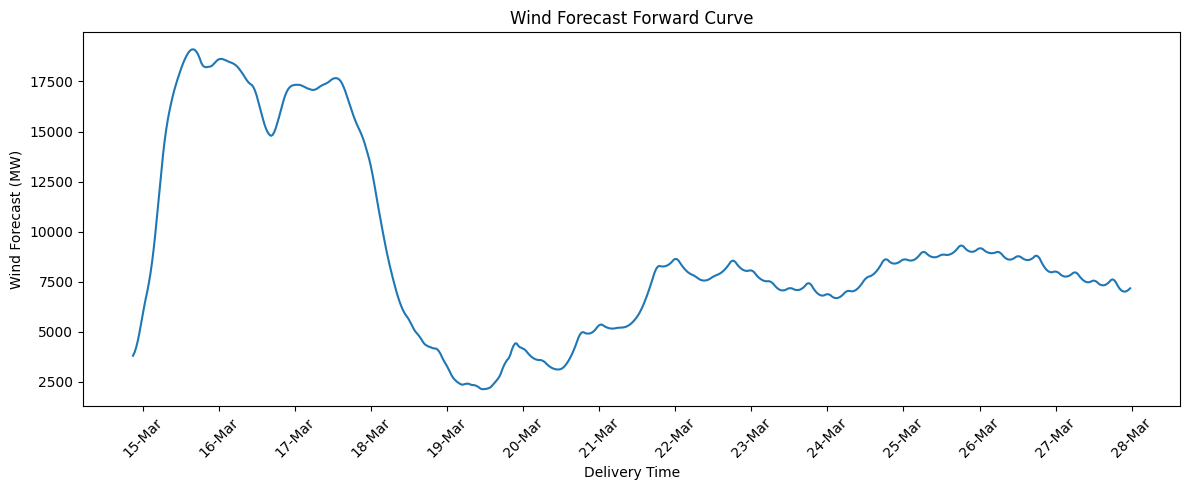

In [5]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df_plot = pd.read_sql("""
SELECT Datetime, Wind_Forecast
FROM wind_forecast
ORDER BY Datetime
""", conn)

df_plot["Datetime"] = pd.to_datetime(df_plot["Datetime"])

plt.figure(figsize=(12,5))
plt.plot(df_plot["Datetime"], df_plot["Wind_Forecast"])

plt.title("Wind Forecast Forward Curve")
plt.xlabel("Delivery Time")
plt.ylabel("Wind Forecast (MW)")

# Format time axis
plt.gca().xaxis.set_major_locator(mdates.DayLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()



In [12]:
df_plot["Wind_Utilisation"] = df_plot["Wind_Forecast"] / 24004

df_plot.head()


,Datetime,Wind_Forecast,Wind_Utilisation
0,2026-03-14 21:00:00,3799,0.158265
1,2026-03-14 21:30:00,3968,0.165306
2,2026-03-14 22:00:00,4213,0.175512
3,2026-03-14 22:30:00,4536,0.188969
4,2026-03-14 23:00:00,4919,0.204924


In [13]:
df_plot["Wind_Utilisation_pct"] = df_plot["Wind_Utilisation"] * 100

df_plot[["Datetime","Wind_Utilisation_pct"]].head()


,Datetime,Wind_Utilisation_pct
0,2026-03-14 21:00:00,15.826529
1,2026-03-14 21:30:00,16.530578
2,2026-03-14 22:00:00,17.551241
3,2026-03-14 22:30:00,18.896851
4,2026-03-14 23:00:00,20.492418


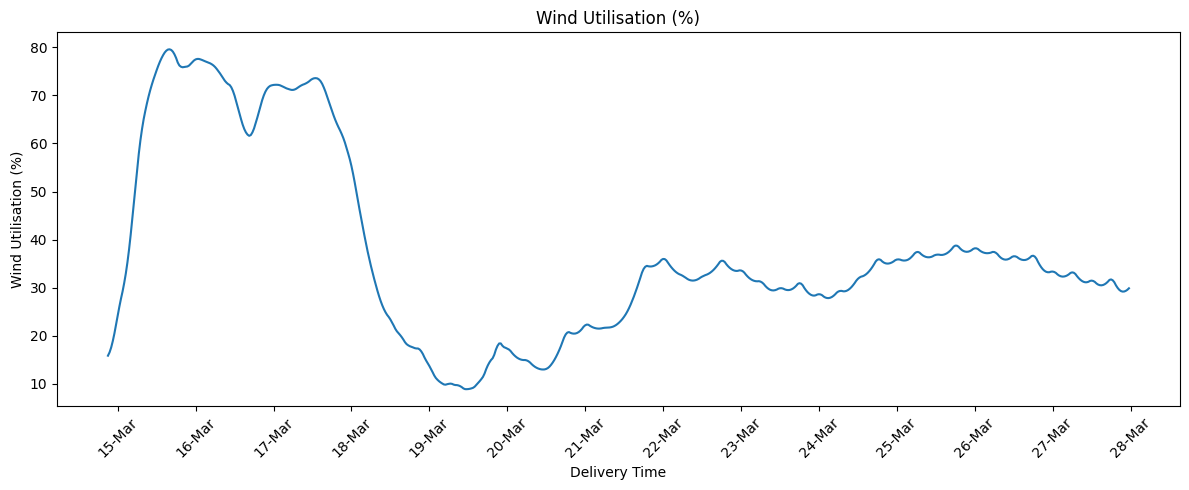

In [14]:
plt.figure(figsize=(12,5))

plt.plot(df_plot["Datetime"], df_plot["Wind_Utilisation_pct"])

plt.title("Wind Utilisation (%)")
plt.xlabel("Delivery Time")
plt.ylabel("Wind Utilisation (%)")

plt.gca().xaxis.set_major_locator(mdates.DayLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [15]:
df_plot.loc[df_plot["Wind_Forecast"].idxmax()]



Datetime                2026-03-15 16:00:00
Wind_Forecast                         19106
Wind_Utilisation                   0.795951
Wind_Utilisation_pct              79.595067
Name: 38, dtype: object

In [16]:
df_plot["Wind_Forecast"].describe()


count      630.000000
mean      8954.647619
std       4649.806725
min       2126.000000
25%       6138.750000
50%       7935.000000
75%       9079.500000
max      19106.000000
Name: Wind_Forecast, dtype: float64

In [17]:
df_plot["Wind_Utilisation_pct"].describe()


count    630.000000
mean      37.304814
std       19.370966
min        8.856857
25%       25.573863
50%       33.056991
75%       37.824946
max       79.595067
Name: Wind_Utilisation_pct, dtype: float64

In [1]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("../db/market_data.db")


In [2]:
pd.read_sql("SELECT * FROM demand LIMIT 10;", conn)


,Datetime,Demand
0,2026-03-16 00:30:00,23209
1,2026-03-16 01:00:00,23961
2,2026-03-16 01:30:00,23814
3,2026-03-16 02:00:00,23260
4,2026-03-16 02:30:00,22831
5,2026-03-16 03:00:00,22266
6,2026-03-16 03:30:00,21832
7,2026-03-16 04:00:00,21603
8,2026-03-16 04:30:00,21463
9,2026-03-16 05:00:00,21490


In [3]:
pd.read_sql("""
SELECT
    (SELECT MIN(Datetime) FROM wind_forecast) AS wind_min,
    (SELECT MAX(Datetime) FROM wind_forecast) AS wind_max,
    (SELECT MIN(Datetime) FROM demand) AS demand_min,
    (SELECT MAX(Datetime) FROM demand) AS demand_max;
""", conn)


,wind_min,wind_max,demand_min,demand_max
0,2026-03-14 21:00:00,2026-03-27 23:30:00,2026-03-16 00:30:00,2026-03-29 00:00:00


In [4]:
df_model = pd.read_sql("""
SELECT
    w.Datetime,
    w.Wind_Forecast,
    w.Capacity,
    d.Demand
FROM wind_forecast w
JOIN demand d
ON w.Datetime = d.Datetime
ORDER BY w.Datetime
""", conn)

df_model.head()


,Datetime,Wind_Forecast,Capacity,Demand
0,2026-03-16 00:30:00,18626,24004,23209
1,2026-03-16 01:00:00,18626,24004,23961
2,2026-03-16 01:30:00,18603,24004,23814
3,2026-03-16 02:00:00,18573,24004,23260
4,2026-03-16 02:30:00,18536,24004,22831


In [5]:
df_model.shape


(575, 4)

In [6]:
df_model["Residual_Demand"] = df_model["Demand"] - df_model["Wind_Forecast"]

df_model.head()


,Datetime,Wind_Forecast,Capacity,Demand,Residual_Demand
0,2026-03-16 00:30:00,18626,24004,23209,4583
1,2026-03-16 01:00:00,18626,24004,23961,5335
2,2026-03-16 01:30:00,18603,24004,23814,5211
3,2026-03-16 02:00:00,18573,24004,23260,4687
4,2026-03-16 02:30:00,18536,24004,22831,4295


In [7]:
df_model["Residual_Demand"].describe()


count      575.000000
mean     19971.749565
std       6077.091617
min       3058.000000
25%      16203.000000
50%      20484.000000
75%      23881.500000
max      33107.000000
Name: Residual_Demand, dtype: float64

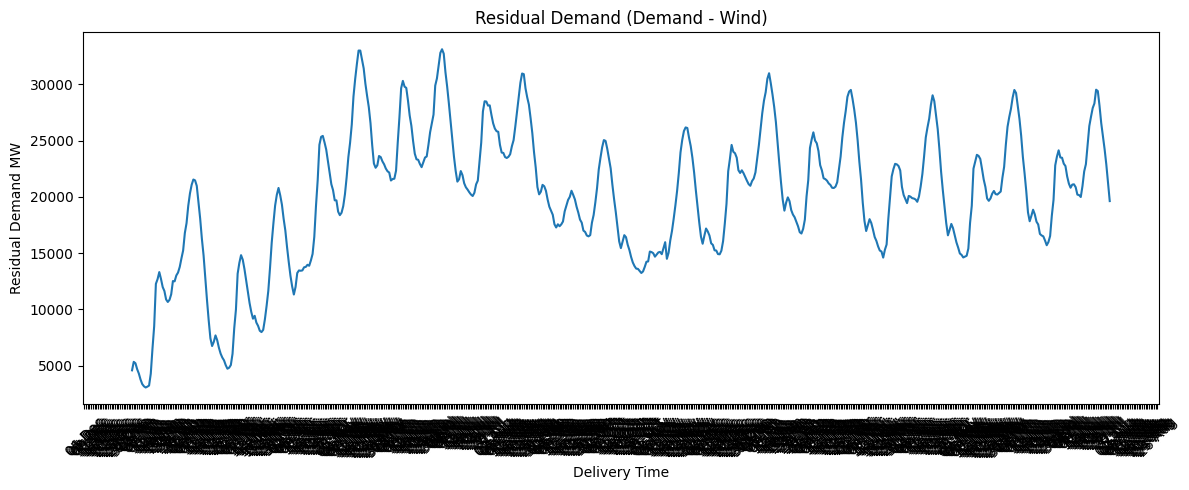

In [8]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(12,5))

plt.plot(df_model["Datetime"], df_model["Residual_Demand"])

plt.title("Residual Demand (Demand - Wind)")
plt.xlabel("Delivery Time")
plt.ylabel("Residual Demand MW")

plt.gca().xaxis.set_major_locator(mdates.DayLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [9]:
df_model[["Datetime","Residual_Demand"]].head(10)


,Datetime,Residual_Demand
0,2026-03-16 00:30:00,4583
1,2026-03-16 01:00:00,5335
2,2026-03-16 01:30:00,5211
3,2026-03-16 02:00:00,4687
4,2026-03-16 02:30:00,4295
5,2026-03-16 03:00:00,3763
6,2026-03-16 03:30:00,3360
7,2026-03-16 04:00:00,3164
8,2026-03-16 04:30:00,3058
9,2026-03-16 05:00:00,3132


In [12]:
df_model["Datetime"] = pd.to_datetime(df_model["Datetime"])
df_model.dtypes


Datetime           datetime64[us]
Wind_Forecast               int64
Capacity                    int64
Demand                      int64
Residual_Demand             int64
dtype: object

In [13]:
df_plot2 = df_model.copy()
df_plot2["Datetime"] = pd.to_datetime(df_plot2["Datetime"])
df_plot2 = df_plot2.set_index("Datetime")
df_plot2.head()


,Wind_Forecast,Capacity,Demand,Residual_Demand
Datetime,,,,
2026-03-16 00:30:00,18626,24004,23209,4583
2026-03-16 01:00:00,18626,24004,23961,5335
2026-03-16 01:30:00,18603,24004,23814,5211
2026-03-16 02:00:00,18573,24004,23260,4687
2026-03-16 02:30:00,18536,24004,22831,4295


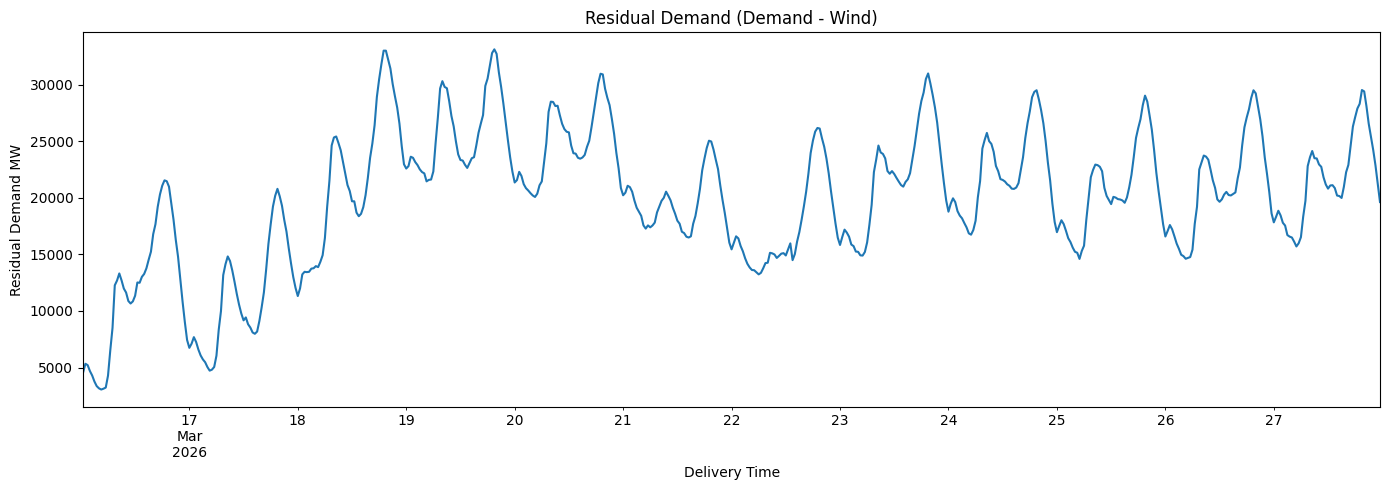

In [14]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(14, 5))

df_plot2["Residual_Demand"].plot(ax=ax)

ax.set_title("Residual Demand (Demand - Wind)")
ax.set_xlabel("Delivery Time")
ax.set_ylabel("Residual Demand MW")

ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [15]:
def classify_residual(x):
    
    if x < 5000:
        return "Extreme oversupply"
    
    elif x < 10000:
        return "Oversupplied"
    
    elif x < 20000:
        return "Normal"
    
    elif x < 30000:
        return "Tight"
    
    else:
        return "Very tight"


df_model["System_Regime"] = df_model["Residual_Demand"].apply(classify_residual)

df_model.head()


,Datetime,Wind_Forecast,Capacity,Demand,Residual_Demand,System_Regime
0,2026-03-16 00:30:00,18626,24004,23209,4583,Extreme oversupply
1,2026-03-16 01:00:00,18626,24004,23961,5335,Oversupplied
2,2026-03-16 01:30:00,18603,24004,23814,5211,Oversupplied
3,2026-03-16 02:00:00,18573,24004,23260,4687,Extreme oversupply
4,2026-03-16 02:30:00,18536,24004,22831,4295,Extreme oversupply


In [16]:
df_model["System_Regime"].value_counts()


System_Regime
Tight                 291
Normal                224
Oversupplied           28
Very tight             20
Extreme oversupply     12
Name: count, dtype: int64

<Axes: xlabel='System_Regime'>

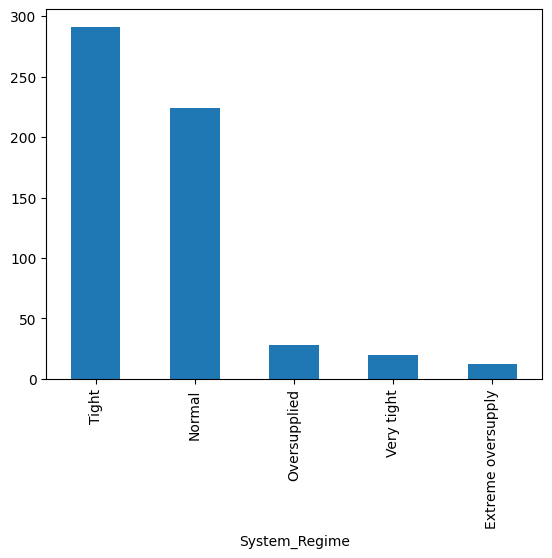

In [17]:
df_model["System_Regime"].value_counts().plot(kind="bar")


In [18]:
df_model.groupby("System_Regime")["Residual_Demand"].mean()


System_Regime
Extreme oversupply     3924.750000
Normal                16295.370536
Oversupplied           7436.500000
Tight                 23885.718213
Very tight            31376.500000
Name: Residual_Demand, dtype: float64

In [19]:
df_model[["Demand","Wind_Forecast","Residual_Demand"]].describe()



,Demand,Wind_Forecast,Residual_Demand
count,575.000000,575.000000,575.000000
mean,28417.266087,8445.516522,19971.749565
std,4201.006861,4246.404553,6077.091617
min,21024.000000,2126.000000,3058.000000
25%,24869.500000,5686.000000,16203.000000
50%,28270.000000,7794.000000,20484.000000
75%,31363.000000,8861.000000,23881.500000
max,38173.000000,18626.000000,33107.000000


In [20]:
df_model.corr(numeric_only=True)


,Wind_Forecast,Capacity,Demand,Residual_Demand
Wind_Forecast,1.000000,NaN,-0.035053,-0.722988
Capacity,NaN,NaN,NaN,NaN
Demand,-0.035053,NaN,1.000000,0.715779
Residual_Demand,-0.722988,NaN,0.715779,1.000000


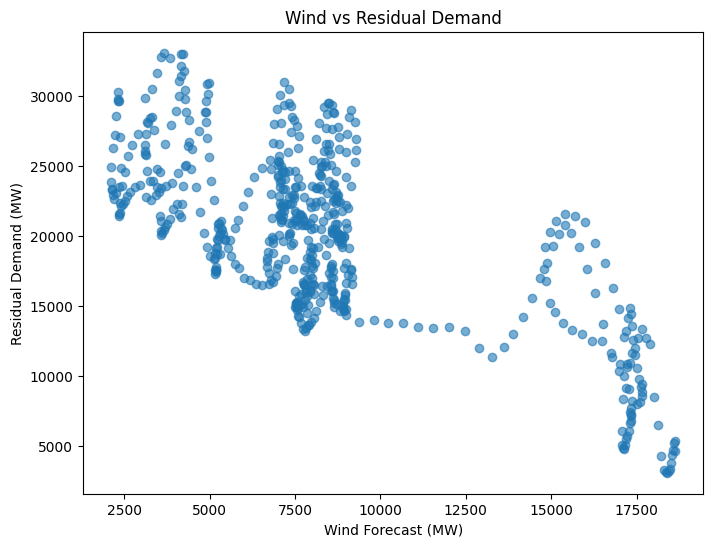

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(df_model["Wind_Forecast"], df_model["Residual_Demand"], alpha=0.6)

plt.xlabel("Wind Forecast (MW)")
plt.ylabel("Residual Demand (MW)")
plt.title("Wind vs Residual Demand")

plt.show()


In [22]:
df_model[["Wind_Forecast","Residual_Demand"]].corr()


,Wind_Forecast,Residual_Demand
Wind_Forecast,1.000000,-0.722988
Residual_Demand,-0.722988,1.000000


In [2]:
import pandas as pd


In [3]:
hist_wind = pd.read_csv("../data/historical_wind_clean.csv")
hist_demand = pd.read_csv("../data/historical_demand_clean.csv")

hist_wind["Datetime"] = pd.to_datetime(hist_wind["Datetime"])
hist_demand["Datetime"] = pd.to_datetime(hist_demand["Datetime"])

hist_model = hist_demand.merge(hist_wind, on="Datetime", how="inner")

hist_model["Residual_Demand"] = hist_model["Demand"] - hist_model["Wind_Actual"]

hist_model.head()



,Datetime,Settlement_Period_x,Demand,Settlement_Period_y,Wind_Actual,Residual_Demand
0,2026-03-14 00:00:00+00:00,1,28584,1,8174,20410
1,2026-03-14 00:30:00+00:00,2,29016,2,8033,20983
2,2026-03-14 01:00:00+00:00,3,28456,3,7751,20705
3,2026-03-14 01:30:00+00:00,4,27875,4,7604,20271
4,2026-03-14 02:00:00+00:00,5,27383,5,7236,20147


In [4]:
hist_model.shape

(47, 6)

In [5]:
hist_wind["Datetime"].min(), hist_wind["Datetime"].max(), hist_wind.shape

(Timestamp('2026-03-14 00:00:00+0000', tz='UTC'),
 Timestamp('2026-03-14 23:00:00+0000', tz='UTC'),
 (47, 3))

In [6]:
hist_demand["Datetime"].min(), hist_demand["Datetime"].max(), hist_demand.shape

(Timestamp('2026-02-14 00:00:00+0000', tz='UTC'),
 Timestamp('2026-03-14 23:00:00+0000', tz='UTC'),
 (1391, 3))

In [7]:
hist_model["Datetime"].min(), hist_model["Datetime"].max(), hist_model.shape

(Timestamp('2026-03-14 00:00:00+0000', tz='UTC'),
 Timestamp('2026-03-14 23:00:00+0000', tz='UTC'),
 (47, 6))

In [8]:
hist_model[["Datetime", "Demand", "Wind_Actual", "Residual_Demand"]].head(20)

,Datetime,Demand,Wind_Actual,Residual_Demand
0,2026-03-14 00:00:00+00:00,28584,8174,20410
1,2026-03-14 00:30:00+00:00,29016,8033,20983
2,2026-03-14 01:00:00+00:00,28456,7751,20705
3,2026-03-14 01:30:00+00:00,27875,7604,20271
4,2026-03-14 02:00:00+00:00,27383,7236,20147
5,2026-03-14 02:30:00+00:00,27006,7034,19972
6,2026-03-14 03:00:00+00:00,26243,6769,19474
7,2026-03-14 03:30:00+00:00,25987,6708,19279
8,2026-03-14 04:00:00+00:00,25799,7055,18744
9,2026-03-14 04:30:00+00:00,25794,6903,18891


In [9]:
hist_model.to_csv("../data/historical_training_sample.csv", index=False)
hist_model.head()

,Datetime,Settlement_Period_x,Demand,Settlement_Period_y,Wind_Actual,Residual_Demand
0,2026-03-14 00:00:00+00:00,1,28584,1,8174,20410
1,2026-03-14 00:30:00+00:00,2,29016,2,8033,20983
2,2026-03-14 01:00:00+00:00,3,28456,3,7751,20705
3,2026-03-14 01:30:00+00:00,4,27875,4,7604,20271
4,2026-03-14 02:00:00+00:00,5,27383,5,7236,20147


In [10]:
hist_model[["Demand", "Wind_Actual", "Residual_Demand"]].describe()

,Demand,Wind_Actual,Residual_Demand
count,47.000000,47.000000,47.000000
mean,27912.851064,5586.212766,22326.638298
std,4438.491518,1293.785311,5145.608733
min,21320.000000,3375.000000,16868.000000
25%,25445.000000,4417.000000,18873.500000
50%,26966.000000,5594.000000,20271.000000
75%,29551.500000,6576.500000,24721.500000
max,37002.000000,8174.000000,33627.000000


In [1]:
price = pd.read_csv("../data/recent_price_clean.csv")

price["Datetime"] = pd.to_datetime(price["Datetime"])

model_price = hist_model.merge(price, on="Datetime", how="inner")

model_price.head()

NameError: name 'pd' is not defined

In [2]:
import pandas as pd

In [3]:
price = pd.read_csv("../data/recent_price_clean.csv")

price["Datetime"] = pd.to_datetime(price["Datetime"])

model_price = hist_model.merge(price, on="Datetime", how="inner")

model_price.head()

NameError: name 'hist_model' is not defined

In [4]:
import pandas as pd

In [5]:
hist_wind = pd.read_csv("../data/historical_wind_clean.csv")
hist_demand = pd.read_csv("../data/historical_demand_clean.csv")

In [6]:
hist_wind["Datetime"] = pd.to_datetime(hist_wind["Datetime"])
hist_demand["Datetime"] = pd.to_datetime(hist_demand["Datetime"])

In [7]:
hist_model = hist_demand.merge(hist_wind, on="Datetime", how="inner")

hist_model.head()

,Datetime,Settlement_Period_x,Demand,Settlement_Period_y,Wind_Actual
0,2026-03-14 00:00:00+00:00,1,28584,1,8174
1,2026-03-14 00:30:00+00:00,2,29016,2,8033
2,2026-03-14 01:00:00+00:00,3,28456,3,7751
3,2026-03-14 01:30:00+00:00,4,27875,4,7604
4,2026-03-14 02:00:00+00:00,5,27383,5,7236


In [8]:
hist_model = hist_demand.merge(hist_wind, on="Datetime", how="inner")

hist_model.head()

,Datetime,Settlement_Period_x,Demand,Settlement_Period_y,Wind_Actual
0,2026-03-14 00:00:00+00:00,1,28584,1,8174
1,2026-03-14 00:30:00+00:00,2,29016,2,8033
2,2026-03-14 01:00:00+00:00,3,28456,3,7751
3,2026-03-14 01:30:00+00:00,4,27875,4,7604
4,2026-03-14 02:00:00+00:00,5,27383,5,7236


In [9]:
hist_model["Residual_Demand"] = hist_model["Demand"] - hist_model["Wind_Actual"]

hist_model.head()

,Datetime,Settlement_Period_x,Demand,Settlement_Period_y,Wind_Actual,Residual_Demand
0,2026-03-14 00:00:00+00:00,1,28584,1,8174,20410
1,2026-03-14 00:30:00+00:00,2,29016,2,8033,20983
2,2026-03-14 01:00:00+00:00,3,28456,3,7751,20705
3,2026-03-14 01:30:00+00:00,4,27875,4,7604,20271
4,2026-03-14 02:00:00+00:00,5,27383,5,7236,20147


In [10]:
price = pd.read_csv("../data/recent_price_clean.csv")

price["Datetime"] = pd.to_datetime(price["Datetime"])

In [11]:
model_price = hist_model.merge(price, on="Datetime", how="inner")

model_price.head()

,Datetime,Settlement_Period_x,Demand,Settlement_Period_y,Wind_Actual,Residual_Demand,settlementPeriod,Price
0,2026-03-14 00:00:00+00:00,1,28584,1,8174,20410,1,108.77
1,2026-03-14 00:30:00+00:00,2,29016,2,8033,20983,2,110.38
2,2026-03-14 01:00:00+00:00,3,28456,3,7751,20705,3,109.66
3,2026-03-14 01:30:00+00:00,4,27875,4,7604,20271,4,104.91
4,2026-03-14 02:00:00+00:00,5,27383,5,7236,20147,5,104.82


In [12]:
model_price.shape

(47, 8)

In [13]:
model_price[["Residual_Demand","Price"]].corr()

,Residual_Demand,Price
Residual_Demand,1.000000,0.888869
Price,0.888869,1.000000


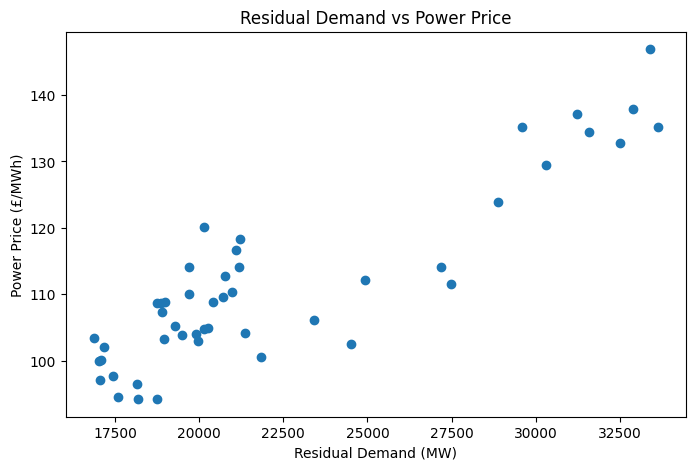

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.scatter(
    model_price["Residual_Demand"],
    model_price["Price"]
)

plt.xlabel("Residual Demand (MW)")
plt.ylabel("Power Price (£/MWh)")
plt.title("Residual Demand vs Power Price")

plt.show()

In [15]:
import numpy as np

x = model_price["Residual_Demand"]
y = model_price["Price"]

coefficients = np.polyfit(x, y, 1)

slope = coefficients[0]
intercept = coefficients[1]

print("Slope:", slope)
print("Intercept:", intercept)

Slope: 0.002277541942818505
Intercept: 60.666102281266305


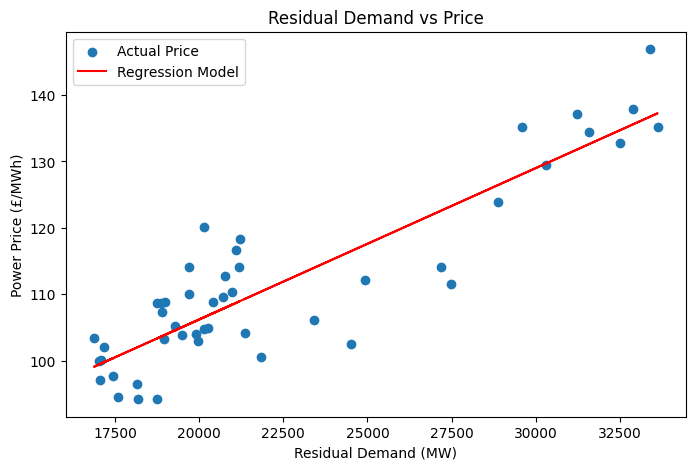

In [16]:
import matplotlib.pyplot as plt
import numpy as np

x = model_price["Residual_Demand"]
y = model_price["Price"]

predicted = slope * x + intercept

plt.figure(figsize=(8,5))

plt.scatter(x, y, label="Actual Price")

plt.plot(x, predicted, color="red", label="Regression Model")

plt.xlabel("Residual Demand (MW)")
plt.ylabel("Power Price (£/MWh)")
plt.title("Residual Demand vs Price")

plt.legend()

plt.show()

In [17]:
wind_price_sensitivity = model_price[["Wind_Actual","Price"]].corr()

wind_price_sensitivity

,Wind_Actual,Price
Wind_Actual,1.000000,-0.461517
Price,-0.461517,1.000000


In [18]:
model_price["Predicted_Price"] = slope * model_price["Residual_Demand"] + intercept

model_price[["Residual_Demand","Price","Predicted_Price"]].head()

,Residual_Demand,Price,Predicted_Price
0,20410,108.77,107.150733
1,20983,110.38,108.455765
2,20705,109.66,107.822608
3,20271,104.91,106.834155
4,20147,104.82,106.551740


In [19]:
model_price["Predicted_Price"] = slope * model_price["Residual_Demand"] + intercept

model_price[["Residual_Demand","Price","Predicted_Price"]].head()

,Residual_Demand,Price,Predicted_Price
0,20410,108.77,107.150733
1,20983,110.38,108.455765
2,20705,109.66,107.822608
3,20271,104.91,106.834155
4,20147,104.82,106.551740


In [20]:
model_price["Error"] = model_price["Price"] - model_price["Predicted_Price"]

model_price["Error"].describe()

count    47.000000
mean      0.000000
std       6.040661
min     -14.026876
25%      -2.988912
50%       0.441914
75%       4.699669
max      13.573313
Name: Error, dtype: float64

In [21]:
import numpy as np

x = model_price["Wind_Actual"]
y = model_price["Price"]

coeff = np.polyfit(x, y, 1)

wind_slope = coeff[0]
wind_intercept = coeff[1]

print("Wind slope:", wind_slope)
print("Wind intercept:", wind_intercept)

Wind slope: -0.004703177466767205
Wind intercept: 137.78890745222697


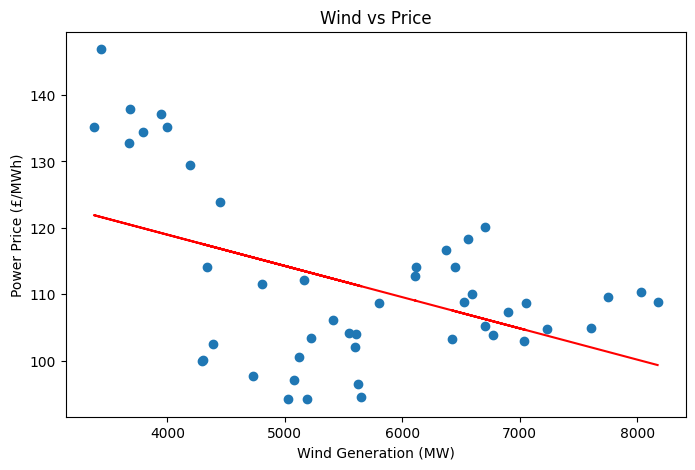

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.scatter(model_price["Wind_Actual"], model_price["Price"])

pred = wind_slope * model_price["Wind_Actual"] + wind_intercept

plt.plot(model_price["Wind_Actual"], pred, color="red")

plt.xlabel("Wind Generation (MW)")
plt.ylabel("Power Price (£/MWh)")
plt.title("Wind vs Price")

plt.show()

In [23]:
wind_forecast = pd.read_csv("../data/neso_wind_full_clean.csv")

wind_forecast["Datetime"] = pd.to_datetime(wind_forecast["Datetime"])

wind_forecast.head()

,Datetime,Wind_Forecast,ForecastDatetime,Settlement_period,Capacity
0,2026-03-14 21:00:00,3799,2026-03-14 20:40:41,43,24004
1,2026-03-14 21:30:00,3968,2026-03-14 20:40:41,44,24004
2,2026-03-14 22:00:00,4213,2026-03-14 20:40:41,45,24004
3,2026-03-14 22:30:00,4536,2026-03-14 20:40:41,46,24004
4,2026-03-14 23:00:00,4919,2026-03-14 20:40:41,47,24004


In [24]:
wind_forecast.describe()

,Datetime,Wind_Forecast,Settlement_period,Capacity
count,630,630.000000,630.000000,630.0
mean,2026-03-21 10:15:00,8954.647619,24.700000,24004.0
min,2026-03-14 21:00:00,2126.000000,1.000000,24004.0
25%,2026-03-18 03:37:30,6138.750000,13.000000,24004.0
50%,2026-03-21 10:15:00,7935.000000,25.000000,24004.0
75%,2026-03-24 16:52:30,9079.500000,37.000000,24004.0
max,2026-03-27 23:30:00,19106.000000,48.000000,24004.0
std,NaN,4649.806725,13.949392,0.0


In [25]:
wind_forecast["Wind_Utilisation"] = wind_forecast["Wind_Forecast"] / 24004

In [26]:
wind_forecast.head()

,Datetime,Wind_Forecast,ForecastDatetime,Settlement_period,Capacity,Wind_Utilisation
0,2026-03-14 21:00:00,3799,2026-03-14 20:40:41,43,24004,0.158265
1,2026-03-14 21:30:00,3968,2026-03-14 20:40:41,44,24004,0.165306
2,2026-03-14 22:00:00,4213,2026-03-14 20:40:41,45,24004,0.175512
3,2026-03-14 22:30:00,4536,2026-03-14 20:40:41,46,24004,0.188969
4,2026-03-14 23:00:00,4919,2026-03-14 20:40:41,47,24004,0.204924


In [27]:
wind_forecast["Datetime"].min(), wind_forecast["Datetime"].max()


(Timestamp('2026-03-14 21:00:00'), Timestamp('2026-03-27 23:30:00'))

In [28]:
wind_forecast["Datetime"].min(), wind_forecast["Datetime"].max()

(Timestamp('2026-03-14 21:00:00'), Timestamp('2026-03-27 23:30:00'))

In [1]:
import pandas as pd

wind_forecast = pd.read_csv("../data/neso_wind_full_clean.csv")
demand_forecast = pd.read_csv("../data/neso_demand_forecast_clean.csv")

wind_forecast["Datetime"] = pd.to_datetime(wind_forecast["Datetime"])
demand_forecast["Datetime"] = pd.to_datetime(demand_forecast["Datetime"])

future_model = wind_forecast.merge(demand_forecast, on="Datetime", how="inner")

future_model["Forecast_Residual_Demand"] = (
    future_model["Forecast_Demand"] - future_model["Wind_Forecast"]
)

future_model["Predicted_Price"] = (
    slope * future_model["Forecast_Residual_Demand"] + intercept
)

future_model.head()

NameError: name 'slope' is not defined

In [2]:
slope = 0.002277541942818505
intercept = 60.666102281266305

In [3]:
future_model["Predicted_Price"] = (
    slope * future_model["Forecast_Residual_Demand"] + intercept
)

In [4]:
future_model.head()

,Datetime,Wind_Forecast,ForecastDatetime,Settlement_period,Capacity,Forecast_Demand,Forecast_Residual_Demand,Predicted_Price
0,2026-03-16 00:30:00,18626,2026-03-14 20:40:41,2,24004,23209,4583,71.104077
1,2026-03-16 01:00:00,18626,2026-03-14 20:40:41,3,24004,23961,5335,72.816789
2,2026-03-16 01:30:00,18603,2026-03-14 20:40:41,4,24004,23814,5211,72.534373
3,2026-03-16 02:00:00,18573,2026-03-14 20:40:41,5,24004,23260,4687,71.340941
4,2026-03-16 02:30:00,18536,2026-03-14 20:40:41,6,24004,22831,4295,70.448145


In [5]:
future_model.shape

(575, 8)

In [6]:
future_model.head()

,Datetime,Wind_Forecast,ForecastDatetime,Settlement_period,Capacity,Forecast_Demand,Forecast_Residual_Demand,Predicted_Price
0,2026-03-16 00:30:00,18626,2026-03-14 20:40:41,2,24004,23209,4583,71.104077
1,2026-03-16 01:00:00,18626,2026-03-14 20:40:41,3,24004,23961,5335,72.816789
2,2026-03-16 01:30:00,18603,2026-03-14 20:40:41,4,24004,23814,5211,72.534373
3,2026-03-16 02:00:00,18573,2026-03-14 20:40:41,5,24004,23260,4687,71.340941
4,2026-03-16 02:30:00,18536,2026-03-14 20:40:41,6,24004,22831,4295,70.448145


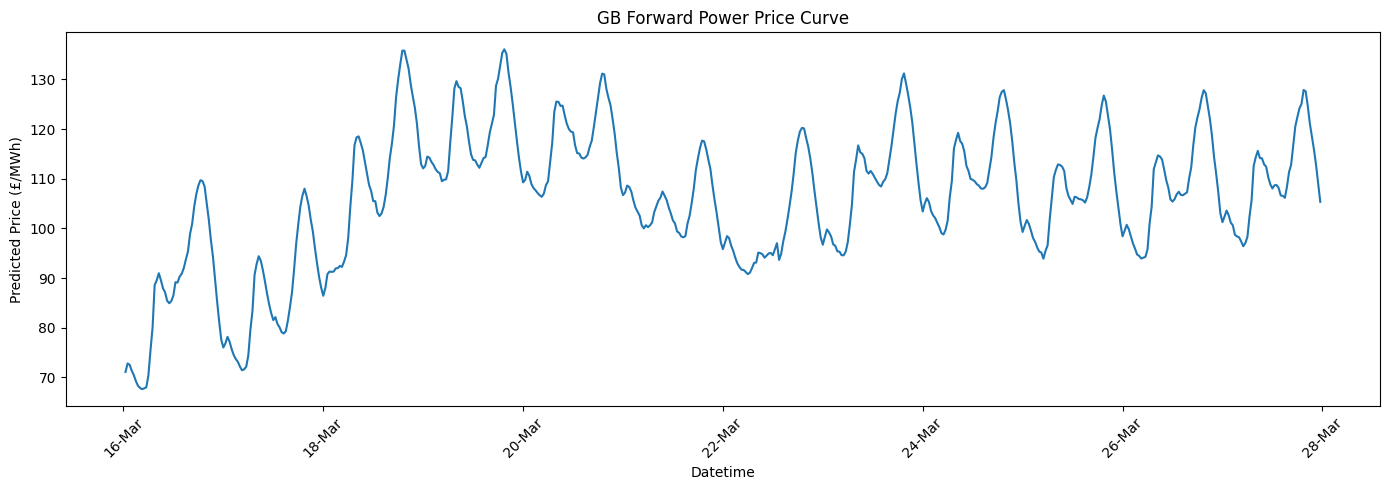

In [7]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(14,5))
plt.plot(future_model["Datetime"], future_model["Predicted_Price"])

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))

plt.xticks(rotation=45)
plt.xlabel("Datetime")
plt.ylabel("Predicted Price (£/MWh)")
plt.title("GB Forward Power Price Curve")
plt.tight_layout()
plt.show()

In [8]:
future_model.loc[future_model["Predicted_Price"].idxmax()]

Datetime                    2026-03-19 19:30:00
Wind_Forecast                              3672
ForecastDatetime            2026-03-14 20:40:41
Settlement_period                            40
Capacity                                  24004
Forecast_Demand                           36779
Forecast_Residual_Demand                  33107
Predicted_Price                      136.068683
Name: 182, dtype: object

In [9]:
future_model.loc[future_model["Predicted_Price"].idxmin()]

Datetime                    2026-03-16 04:30:00
Wind_Forecast                             18405
ForecastDatetime            2026-03-14 20:40:41
Settlement_period                            10
Capacity                                  24004
Forecast_Demand                           21463
Forecast_Residual_Demand                   3058
Predicted_Price                       67.630826
Name: 8, dtype: object

In [10]:
future_model["Predicted_Price"].describe()

count    575.000000
mean     106.152600
std       13.840831
min       67.630826
25%       97.569114
50%      107.319271
75%      115.057220
max      136.068683
Name: Predicted_Price, dtype: float64

In [11]:
future_model.to_csv("../data/forward_price_curve.csv", index=False)

print("Forward price curve saved to data/forward_price_curve.csv")

Forward price curve saved to data/forward_price_curve.csv


In [12]:
import sqlite3

conn = sqlite3.connect("../data/power_market.db")

future_model.to_sql(
    "forward_price_curve",
    conn,
    if_exists="replace",
    index=False
)

print("Saved to SQLite table: forward_price_curve")

Saved to SQLite table: forward_price_curve


In [13]:
def signal_from_residual(x):
    if x >= 30000:
        return "Price Spike Risk"
    elif x >= 25000:
        return "Bullish"
    elif x <= 5000:
        return "Price Collapse Risk"
    elif x <= 10000:
        return "Bearish"
    else:
        return "Neutral"

future_model["Trading_Signal"] = future_model["Forecast_Residual_Demand"].apply(signal_from_residual)

future_model[[
    "Datetime",
    "Wind_Forecast",
    "Forecast_Demand",
    "Forecast_Residual_Demand",
    "Predicted_Price",
    "Trading_Signal"
]].head(20)

,Datetime,Wind_Forecast,Forecast_Demand,Forecast_Residual_Demand,Predicted_Price,Trading_Signal
0,2026-03-16 00:30:00,18626,23209,4583,71.104077,Price Collapse Risk
1,2026-03-16 01:00:00,18626,23961,5335,72.816789,Bearish
2,2026-03-16 01:30:00,18603,23814,5211,72.534373,Bearish
3,2026-03-16 02:00:00,18573,23260,4687,71.340941,Price Collapse Risk
4,2026-03-16 02:30:00,18536,22831,4295,70.448145,Price Collapse Risk
5,2026-03-16 03:00:00,18503,22266,3763,69.236493,Price Collapse Risk
6,2026-03-16 03:30:00,18472,21832,3360,68.318643,Price Collapse Risk
7,2026-03-16 04:00:00,18439,21603,3164,67.872245,Price Collapse Risk
8,2026-03-16 04:30:00,18405,21463,3058,67.630826,Price Collapse Risk
9,2026-03-16 05:00:00,18358,21490,3132,67.799364,Price Collapse Risk


In [14]:
future_model["Trading_Signal"].value_counts()

Trading_Signal
Neutral                423
Bullish                 92
Bearish                 28
Price Spike Risk        20
Price Collapse Risk     12
Name: count, dtype: int64

In [15]:
future_model[
    future_model["Trading_Signal"].isin(["Price Spike Risk", "Price Collapse Risk"])
][[
    "Datetime",
    "Forecast_Residual_Demand",
    "Predicted_Price",
    "Trading_Signal"
]].sort_values("Datetime")

,Datetime,Forecast_Residual_Demand,Predicted_Price,Trading_Signal
0,2026-03-16 00:30:00,4583,71.104077,Price Collapse Risk
3,2026-03-16 02:00:00,4687,71.340941,Price Collapse Risk
4,2026-03-16 02:30:00,4295,70.448145,Price Collapse Risk
5,2026-03-16 03:00:00,3763,69.236493,Price Collapse Risk
6,2026-03-16 03:30:00,3360,68.318643,Price Collapse Risk
7,2026-03-16 04:00:00,3164,67.872245,Price Collapse Risk
8,2026-03-16 04:30:00,3058,67.630826,Price Collapse Risk
9,2026-03-16 05:00:00,3132,67.799364,Price Collapse Risk
10,2026-03-16 05:30:00,3230,68.022563,Price Collapse Risk
11,2026-03-16 06:00:00,4284,70.423092,Price Collapse Risk


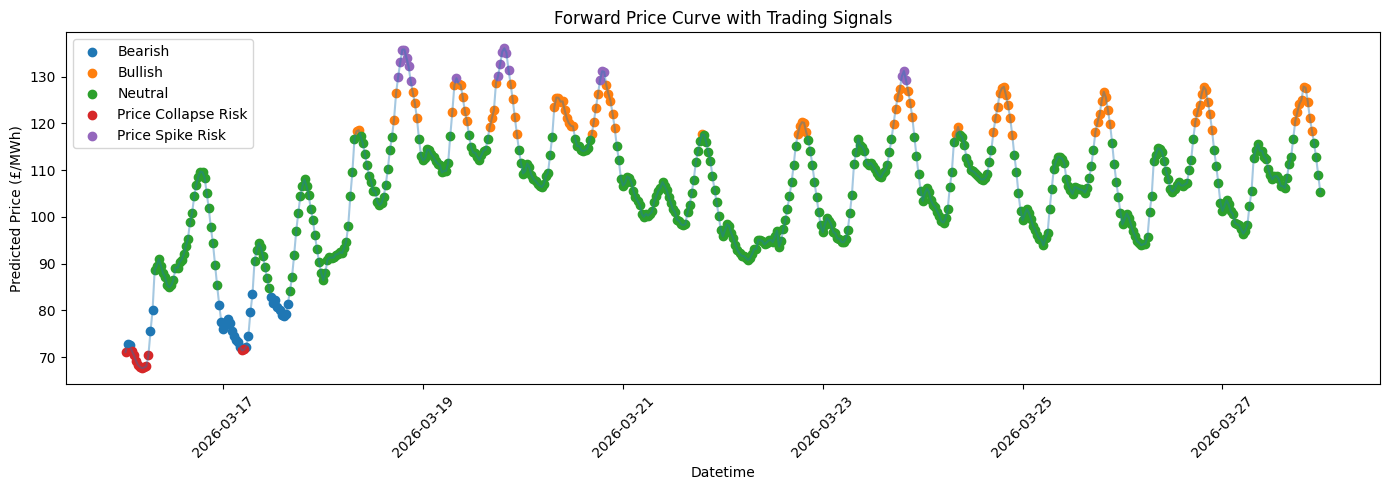

In [16]:
import matplotlib.pyplot as plt

colors = {
    "Price Spike Risk": "red",
    "Bullish": "orange",
    "Neutral": "blue",
    "Bearish": "green",
    "Price Collapse Risk": "purple"
}

plt.figure(figsize=(14,5))

for signal, group in future_model.groupby("Trading_Signal"):
    plt.scatter(
        group["Datetime"],
        group["Predicted_Price"],
        label=signal
    )

plt.plot(future_model["Datetime"], future_model["Predicted_Price"], alpha=0.4)

plt.xlabel("Datetime")
plt.ylabel("Predicted Price (£/MWh)")
plt.title("Forward Price Curve with Trading Signals")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
future_model.to_csv("../data/forward_price_curve_with_signals.csv", index=False)

import sqlite3
conn = sqlite3.connect("../data/power_market.db")
future_model.to_sql("forward_price_curve_with_signals", conn, if_exists="replace", index=False)
conn.close()

print("Saved signals to CSV and SQLite")

Saved signals to CSV and SQLite


In [18]:
future_model.sort_values("Predicted_Price", ascending=False)[
    ["Datetime","Predicted_Price","Forecast_Residual_Demand","Trading_Signal"]
].head(10)

,Datetime,Predicted_Price,Forecast_Residual_Demand,Trading_Signal
182,2026-03-19 19:30:00,136.068683,33107,Price Spike Risk
133,2026-03-18 19:00:00,135.806766,32992,Price Spike Risk
134,2026-03-18 19:30:00,135.799933,32989,Price Spike Risk
181,2026-03-19 19:00:00,135.335315,32785,Price Spike Risk
183,2026-03-19 20:00:00,135.164499,32710,Price Spike Risk
135,2026-03-18 20:00:00,133.973345,32187,Price Spike Risk
132,2026-03-18 18:30:00,133.062328,31787,Price Spike Risk
180,2026-03-19 18:30:00,132.757137,31653,Price Spike Risk
136,2026-03-18 20:30:00,132.199140,31408,Price Spike Risk
184,2026-03-19 20:30:00,131.429330,31070,Price Spike Risk


In [19]:
gas = pd.read_csv("../data/gas_price_clean.csv")

gas["Datetime"] = pd.to_datetime(gas["Datetime"])

gas.head()

,Datetime,Gas_Price
0,1987-05-20,18.63
1,1987-05-21,18.45
2,1987-05-22,18.55
3,1987-05-25,18.60
4,1987-05-26,18.63


In [22]:
hist_model = pd.read_csv("../data/historical_model.csv")

FileNotFoundError: [Errno 2] No such file or directory: '../data/historical_model.csv'

In [23]:
import pandas as pd

hist_wind = pd.read_csv("../data/historical_wind_clean.csv")
hist_demand = pd.read_csv("../data/historical_demand_clean.csv")
price = pd.read_csv("../data/recent_price_clean.csv")

hist_wind["Datetime"] = pd.to_datetime(hist_wind["Datetime"])
hist_demand["Datetime"] = pd.to_datetime(hist_demand["Datetime"])
price["Datetime"] = pd.to_datetime(price["Datetime"])

In [24]:
hist_model = hist_demand.merge(hist_wind, on="Datetime", how="inner")

hist_model["Residual_Demand"] = (
    hist_model["Demand"] - hist_model["Wind_Actual"]
)

hist_model.head()

,Datetime,Settlement_Period_x,Demand,Settlement_Period_y,Wind_Actual,Residual_Demand
0,2026-03-14 00:00:00+00:00,1,28584,1,8174,20410
1,2026-03-14 00:30:00+00:00,2,29016,2,8033,20983
2,2026-03-14 01:00:00+00:00,3,28456,3,7751,20705
3,2026-03-14 01:30:00+00:00,4,27875,4,7604,20271
4,2026-03-14 02:00:00+00:00,5,27383,5,7236,20147


In [25]:
hist_model = hist_model.merge(price, on="Datetime", how="inner")

hist_model = hist_model.rename(columns={"price": "Price"})

hist_model.head()


,Datetime,Settlement_Period_x,Demand,Settlement_Period_y,Wind_Actual,Residual_Demand,settlementPeriod,Price
0,2026-03-14 00:00:00+00:00,1,28584,1,8174,20410,1,108.77
1,2026-03-14 00:30:00+00:00,2,29016,2,8033,20983,2,110.38
2,2026-03-14 01:00:00+00:00,3,28456,3,7751,20705,3,109.66
3,2026-03-14 01:30:00+00:00,4,27875,4,7604,20271,4,104.91
4,2026-03-14 02:00:00+00:00,5,27383,5,7236,20147,5,104.82


In [26]:
hist_model.to_csv("../data/historical_model_dataset.csv", index=False)

print("Historical model dataset saved")

Historical model dataset saved


In [27]:
hist_model.to_csv("../data/historical_model_dataset.csv", index=False)

print("Historical model dataset saved")

Historical model dataset saved


In [28]:
gas = pd.read_csv("../data/gas_price_clean.csv")

gas["Datetime"] = pd.to_datetime(gas["Datetime"])

In [29]:
hist_model = hist_model.merge(gas, on="Datetime", how="left")

hist_model["Gas_Price"] = hist_model["Gas_Price"].ffill()

hist_model.head()


ValueError: You are trying to merge on datetime64[us, UTC] and datetime64[us] columns for key 'Datetime'. If you wish to proceed you should use pd.concat

In [30]:
hist_model["Datetime"] = pd.to_datetime(hist_model["Datetime"]).dt.tz_localize(None)
gas["Datetime"] = pd.to_datetime(gas["Datetime"]).dt.tz_localize(None)

In [31]:
hist_model = hist_model.merge(gas, on="Datetime", how="left")

hist_model["Gas_Price"] = hist_model["Gas_Price"].ffill()

hist_model.head()

,Datetime,Settlement_Period_x,Demand,Settlement_Period_y,Wind_Actual,Residual_Demand,settlementPeriod,Price,Gas_Price
0,2026-03-14 00:00:00,1,28584,1,8174,20410,1,108.77,NaN
1,2026-03-14 00:30:00,2,29016,2,8033,20983,2,110.38,NaN
2,2026-03-14 01:00:00,3,28456,3,7751,20705,3,109.66,NaN
3,2026-03-14 01:30:00,4,27875,4,7604,20271,4,104.91,NaN
4,2026-03-14 02:00:00,5,27383,5,7236,20147,5,104.82,NaN


In [32]:
gas.head(10)

,Datetime,Gas_Price
0,1987-05-20,18.63
1,1987-05-21,18.45
2,1987-05-22,18.55
3,1987-05-25,18.60
4,1987-05-26,18.63
5,1987-05-27,18.60
6,1987-05-28,18.60
7,1987-05-29,18.58
8,1987-06-01,18.65
9,1987-06-02,18.68


In [33]:
gas.head(10)

,Datetime,Gas_Price
0,1987-05-20,18.63
1,1987-05-21,18.45
2,1987-05-22,18.55
3,1987-05-25,18.60
4,1987-05-26,18.63
5,1987-05-27,18.60
6,1987-05-28,18.60
7,1987-05-29,18.58
8,1987-06-01,18.65
9,1987-06-02,18.68


In [34]:
gas["Datetime"].min(), gas["Datetime"].max(), gas.shape


(Timestamp('1987-05-20 00:00:00'), Timestamp('2026-03-09 00:00:00'), (9846, 2))

In [35]:
gas.isna().sum()

Datetime     0
Gas_Price    0
dtype: int64